# FarmTech Solutions | Fase 6: Entrega 2
**YOLO customizado x YOLO padrão x CNN treinada do zero**

**Aluna:** Natalia Faro - RM 568610

## 1. Objetivo
Na Entrega 1, treinei um **YOLOv5 customizado** para detectar bananas e cadernos. Nesta entrega, comparo esse resultado com outras duas abordagens, usando **a mesma base de 80 imagens e a mesma divisão** (64 treino / 8 validação / 8 teste):

| | Abordagem | Descrição | Treino |
|---|---|---|---|
| **A** | YOLO customizado | YOLOv5s ajustado (*fine-tuning*) com as minhas imagens, treinado com 30 e 60 épocas (Entrega 1) | feito na Entrega 1 |
| **B** | YOLO padrão | YOLOv5s original, pré-treinado no COCO, **sem nenhum ajuste** | nenhum |
| **C** | CNN do zero | Rede convolucional simples em PyTorch, treinada só com as minhas 64 imagens, que classifica a imagem inteira como `banana` ou `caderno` | feito neste notebook |

## 2. Como comparar abordagens diferentes
O YOLO **desenha caixas** e a CNN **só classifica a imagem inteira**. O ponto em comum é a **classificação da imagem**, então a métrica principal é a **acurácia por imagem**:
- **CNN:** a classe prevista para a imagem.
- **YOLO:** a classe da detecção com maior confiança na imagem. Se nada for detectado, conta como erro.
- **YOLO padrão (B):** o COCO tem `banana`, mas **não tem `caderno`**. Considero `book` (livro) como o equivalente mais próximo e ignoro as demais classes do COCO.

Como esse não é o único ponto de vista, também comparo, para cada abordagem: facilidade de uso/integração, precisão, tempo de treinamento/customização e tempo de inferência.

> **Cuidado com o tamanho do teste:** são só 8 imagens, então cada acerto ou erro muda a acurácia em 12,5 pontos percentuais. As conclusões devem ser lidas com essa cautela.

> **Antes de rodar:** ative a GPU em *Ambiente de execução → Alterar tipo de ambiente de execução → GPU (T4)*. Para o YOLO customizado (A), os pesos `best.pt` da Entrega 1 precisam estar no Drive, em `FarmTech_YOLO/resultados_runs/train/`.

## Etapa 1: Preparar o dataset
Conecto o Drive, copio o dataset para o disco local (mais rápido) e confiro as quantidades. O rótulo de cada imagem para a CNN vem do **nome do arquivo** (`banana_...` = 0, `caderno_...` = 1), a mesma ordem das classes usada no YOLO. Como cada foto tem só um tipo de objeto, não é preciso rotular de novo.

In [1]:
# Monta o Google Drive no Colab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, shutil, time, random, glob
import numpy as np

# Caminho do dataset no Drive e cópia local (mais rápida para treinar)
DRIVE_DATASET = '/content/drive/MyDrive/FarmTech_YOLO'
LOCAL_DATASET = '/content/FarmTech_YOLO'

# Copia o dataset, ignorando a pasta de resultados da Entrega 1 (pesada)
if os.path.exists(LOCAL_DATASET):
    shutil.rmtree(LOCAL_DATASET)
shutil.copytree(DRIVE_DATASET, LOCAL_DATASET, ignore=shutil.ignore_patterns('resultados_runs'))
print('Dataset copiado para', LOCAL_DATASET)

Dataset copiado para /content/FarmTech_YOLO


In [3]:
CLASSES = ['banana', 'caderno']  # índice 0 = banana, índice 1 = caderno

def listar(etapa):
    # Lista os caminhos das imagens de uma etapa (train, val ou test)
    pasta = f'{LOCAL_DATASET}/images/{etapa}'
    return sorted(os.path.join(pasta, f) for f in os.listdir(pasta)
                  if f.lower().endswith(('.jpg', '.jpeg', '.png')))

def rotulo(caminho):
    # O nome do arquivo define a classe: banana_... -> 0, caderno_... -> 1
    return 0 if os.path.basename(caminho).startswith('banana') else 1

# Confere a divisão: esperado 64 / 8 / 8, metade de cada classe
for etapa in ('train', 'val', 'test'):
    arqs = listar(etapa)
    n_banana = sum(rotulo(a) == 0 for a in arqs)
    print(f'{etapa:5s} | imagens: {len(arqs):2d} | banana: {n_banana:2d} | caderno: {len(arqs) - n_banana:2d}')

train | imagens: 64 | banana: 32 | caderno: 32
val   | imagens:  8 | banana:  4 | caderno:  4
test  | imagens:  8 | banana:  4 | caderno:  4


## Etapa 2: Instalar o YOLOv5 e carregar o PyTorch
Clono o repositório oficial da Ultralytics, que será usado para carregar os modelos YOLO (A e B). Também fixo as sementes aleatórias para o resultado ser reproduzível.

In [4]:
# Clona o YOLOv5 e instala as dependências
!git clone -q https://github.com/ultralytics/yolov5 /content/yolov5
%cd /content/yolov5
!pip install -q -r requirements.txt

/content/yolov5
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 8.1 MB/s eta 0:00:00


In [5]:
import torch

# Sementes fixas para reprodutibilidade
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Usa a GPU se estiver disponível
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Dispositivo:', device, '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU')

PyTorch: 2.11.0+cu130
Dispositivo: cuda | Tesla T4


## Etapa 3: Abordagens A e B (YOLO)
Carrego três modelos YOLO com o mesmo mecanismo (`torch.hub`), usando o mesmo limiar de confiança de 0,25 da Entrega 1:

- **A (30 e 60 épocas):** os `best.pt` treinados na Entrega 1 com as minhas imagens;
- **B:** o `yolov5s.pt` original, treinado no COCO (80 classes), **sem nenhum ajuste**.

In [6]:
# Pesos treinados na Entrega 1 (salvos no Drive na Etapa 9 do notebook anterior)
PESOS_30 = f'{DRIVE_DATASET}/resultados_runs/train/banana_caderno_30ep/weights/best.pt'
PESOS_60 = f'{DRIVE_DATASET}/resultados_runs/train/banana_caderno_60ep/weights/best.pt'
for p in (PESOS_30, PESOS_60):
    print('existe' if os.path.exists(p) else 'NÃO ENCONTRADO', '->', p)

existe -> /content/drive/MyDrive/FarmTech_YOLO/resultados_runs/train/banana_caderno_30ep/weights/best.pt
existe -> /content/drive/MyDrive/FarmTech_YOLO/resultados_runs/train/banana_caderno_60ep/weights/best.pt


In [7]:
# Abordagem A: YOLO customizado (30 e 60 épocas)
modelo_a30 = torch.hub.load('/content/yolov5', 'custom', path=PESOS_30, source='local')
modelo_a60 = torch.hub.load('/content/yolov5', 'custom', path=PESOS_60, source='local')

# Abordagem B: YOLO padrão, pré-treinado no COCO, sem ajuste
modelo_b = torch.hub.load('/content/yolov5', 'yolov5s', source='local')

# Mesmos limiares de confiança e sobreposição (NMS) da Entrega 1
for m in (modelo_a30, modelo_a60, modelo_b):
    m.conf = 0.25
    m.iou = 0.45

print('Classes do YOLO customizado:', modelo_a30.names)
print('Classes do YOLO padrão (COCO):', len(modelo_b.names), '| banana =', modelo_b.names[46], '| book =', modelo_b.names[73])

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
Adding AutoShape... 
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)



100%|██████████| 14.1M/14.1M [00:00<00:00, 141MB/s]


Fusing layers... 


YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 
Classes do YOLO customizado: {0: 'banana', 1: 'caderno'}
Classes do YOLO padrão (COCO): 80 | banana = banana | book = book


### Como o YOLO vira "classificador de imagem"
Para comparar com a CNN, a função abaixo devolve **uma classe por imagem**: a da detecção com maior confiança. No YOLO padrão, só considero as classes `banana` (46 no COCO) e `book` (73), esta última tratada como `caderno`. Se nenhuma detecção sobra, devolve `-1` ("nada detectado"), que conta como erro.

In [8]:
# Mapa COCO -> minhas classes: banana(46) -> 0, book(73) -> 1 (caderno)
MAPA_COCO = {46: 0, 73: 1}

def prever_yolo(modelo, caminho, mapa=None):
    # Roda o YOLO e devolve a classe da detecção de maior confiança (ou -1 se nada for detectado)
    deteccoes = modelo(caminho, size=640).xyxy[0].cpu().numpy()  # x1, y1, x2, y2, conf, classe
    melhor = None
    for *_, conf, cls in deteccoes:
        c = int(cls)
        if mapa is not None:          # YOLO padrão: ignora classes que não têm equivalente
            if c not in mapa:
                continue
            c = mapa[c]
        if melhor is None or conf > melhor[0]:
            melhor = (conf, c)
    return -1 if melhor is None else melhor[1]

## Etapa 4: Abordagem C, CNN treinada do zero
### 4.1 Dados
Cada imagem é lida (corrigindo a rotação gravada pelo celular), reduzida para **128 x 128 pixels** e guardada na memória. No treino, aplico **data augmentation** (recorte aleatório, espelhamento, rotação e variação de cor), porque 64 imagens são poucas para uma rede aprender do zero. Validação e teste não recebem aumento.

In [9]:
from PIL import Image, ImageOps
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

TAM = 128  # lado da imagem de entrada da CNN

def carregar(caminho):
    # Abre, corrige a rotação do celular (EXIF), converte para RGB e reduz
    img = ImageOps.exif_transpose(Image.open(caminho)).convert('RGB')
    return img.resize((TAM, TAM))

# Normalização padrão (médias e desvios do ImageNet)
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

# Treino: com aumento de dados
tf_treino = transforms.Compose([
    transforms.RandomResizedCrop(TAM, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.ToTensor(), norm])
# Validação e teste: só converter e normalizar
tf_aval = transforms.Compose([transforms.ToTensor(), norm])

class BaseImagens(Dataset):
    # Mantém as imagens reduzidas na memória e aplica a transformação ao pedir cada item
    def __init__(self, caminhos, tf):
        self.imgs = [carregar(c) for c in caminhos]
        self.y = [rotulo(c) for c in caminhos]
        self.tf = tf
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.tf(self.imgs[i]), self.y[i]

dl_treino = DataLoader(BaseImagens(listar('train'), tf_treino), batch_size=16, shuffle=True)
dl_val = DataLoader(BaseImagens(listar('val'), tf_aval), batch_size=16)
print('Imagens: treino', len(dl_treino.dataset), '| validação', len(dl_val.dataset))

Imagens: treino 64 | validação 8


### 4.2 Arquitetura
Rede pequena, com 4 blocos convolucionais (convolução, normalização, ReLU e *max pooling*), seguidos de média global, *dropout* e uma camada final com 2 saídas (banana e caderno). Mantenho a rede simples de propósito, porque há poucos dados.

In [10]:
def bloco(entrada, saida):
    # Convolução 3x3 + normalização + ReLU + redução pela metade
    return nn.Sequential(
        nn.Conv2d(entrada, saida, 3, padding=1),
        nn.BatchNorm2d(saida),
        nn.ReLU(),
        nn.MaxPool2d(2))

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(bloco(3, 16), bloco(16, 32), bloco(32, 64), bloco(64, 128))
        self.classificador = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 2))
    def forward(self, x):
        return self.classificador(self.features(x))

cnn = CNN().to(device)
print(cnn)
print('Parâmetros:', sum(p.numel() for p in cnn.parameters()))

CNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), strid

### 4.3 Treinamento
Treino por 40 épocas com Adam. A **validação** acompanha o treino e escolhe a melhor época (maior acurácia de validação; empate decidido pela menor perda). O **teste não é usado em nenhum momento do treino**. O tempo de treino é medido.

In [11]:
EPOCAS = 40
crit = nn.CrossEntropyLoss()
opt = torch.optim.Adam(cnn.parameters(), lr=1e-3)
hist = {'loss_treino': [], 'acc_treino': [], 'loss_val': [], 'acc_val': []}

def passar(loader, treinar):
    # Uma passada completa pelos dados; devolve perda e acurácia médias
    cnn.train(treinar)
    soma, acertos, total = 0.0, 0, 0
    with torch.set_grad_enabled(treinar):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            saida = cnn(x)
            perda = crit(saida, y)
            if treinar:
                opt.zero_grad()
                perda.backward()
                opt.step()
            soma += perda.item() * len(y)
            acertos += (saida.argmax(1) == y).sum().item()
            total += len(y)
    return soma / total, acertos / total

melhor_score, melhor_estado = (-1, 0), None
if device.type == 'cuda': torch.cuda.synchronize()
t0 = time.time()

for ep in range(1, EPOCAS + 1):
    l_tr, a_tr = passar(dl_treino, True)
    l_v, a_v = passar(dl_val, False)
    for k, v in zip(hist, (l_tr, a_tr, l_v, a_v)):
        hist[k].append(v)
    # Guarda a melhor época: maior acurácia de validação, depois menor perda
    if (a_v, -l_v) > melhor_score:
        melhor_score = (a_v, -l_v)
        melhor_estado = {k: v.clone() for k, v in cnn.state_dict().items()}
        melhor_ep = ep
    if ep % 5 == 0 or ep == 1:
        print(f'época {ep:2d} | treino: perda {l_tr:.3f} acc {a_tr:.2f} | validação: perda {l_v:.3f} acc {a_v:.2f}')

if device.type == 'cuda': torch.cuda.synchronize()
tempo_cnn = time.time() - t0
cnn.load_state_dict(melhor_estado)  # volta para a melhor época
torch.save(cnn.state_dict(), '/content/cnn_banana_caderno.pt')
print(f'\nMelhor época: {melhor_ep} | tempo de treino da CNN: {tempo_cnn:.0f} s ({tempo_cnn/60:.1f} min)')

época  1 | treino: perda 0.511 acc 0.77 | validação: perda 0.679 acc 0.62
época  5 | treino: perda 0.360 acc 0.81 | validação: perda 1.296 acc 0.75
época 10 | treino: perda 0.326 acc 0.91 | validação: perda 1.732 acc 0.75
época 15 | treino: perda 0.201 acc 0.94 | validação: perda 1.644 acc 0.50
época 20 | treino: perda 0.180 acc 0.94 | validação: perda 1.768 acc 0.62
época 25 | treino: perda 0.222 acc 0.92 | validação: perda 1.764 acc 0.75
época 30 | treino: perda 0.322 acc 0.84 | validação: perda 0.887 acc 0.75
época 35 | treino: perda 0.197 acc 0.92 | validação: perda 1.866 acc 0.75
época 40 | treino: perda 0.223 acc 0.92 | validação: perda 1.308 acc 0.75

Melhor época: 31 | tempo de treino da CNN: 7 s (0.1 min)


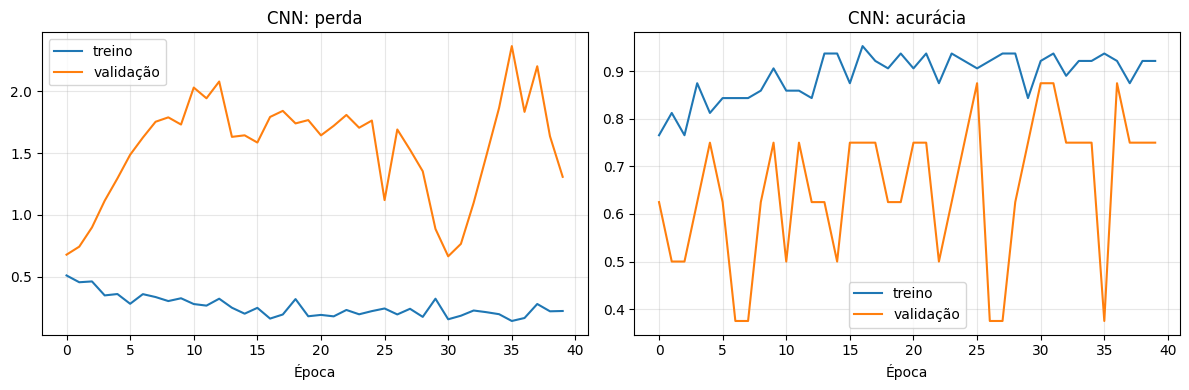

In [12]:
import matplotlib.pyplot as plt

# Curvas de perda e acurácia da CNN
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].plot(hist['loss_treino'], label='treino')
eixos[0].plot(hist['loss_val'], label='validação')
eixos[0].set_title('CNN: perda'); eixos[0].set_xlabel('Época'); eixos[0].legend(); eixos[0].grid(alpha=0.3)
eixos[1].plot(hist['acc_treino'], label='treino')
eixos[1].plot(hist['acc_val'], label='validação')
eixos[1].set_title('CNN: acurácia'); eixos[1].set_xlabel('Época'); eixos[1].legend(); eixos[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig('/content/curvas_cnn.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
# Previsão da CNN para uma imagem (do arquivo até a classe), usada na avaliação e no tempo de inferência
def prever_cnn(caminho):
    x = tf_aval(carregar(caminho)).unsqueeze(0).to(device)
    cnn.eval()
    with torch.no_grad():
        return cnn(x).argmax(1).item()

## Etapa 5: Avaliação das três abordagens
Avalio todos os modelos **do mesmo jeito**: acurácia por imagem em validação e teste, e tabela imagem por imagem no teste.

> **A validação é otimista** para A e C, porque foi usada para escolher o melhor modelo (`best.pt` no YOLO, melhor época na CNN). **O teste é a medida mais honesta**, já que nenhum modelo o viu.

In [14]:
import pandas as pd

# Os quatro modelos avaliados, cada um com a sua função de previsão
preditores = {
    'A) YOLO customizado (30 ép.)': lambda c: prever_yolo(modelo_a30, c),
    'A) YOLO customizado (60 ép.)': lambda c: prever_yolo(modelo_a60, c),
    'B) YOLO padrão (COCO)':        lambda c: prever_yolo(modelo_b, c, MAPA_COCO),
    'C) CNN do zero':               prever_cnn,
}

nome_classe = {-1: 'nada', 0: 'banana', 1: 'caderno'}
acuracia, previsoes = {}, {}
for nome, pred in preditores.items():
    for etapa in ('val', 'test'):
        arqs = listar(etapa)
        verdade = [rotulo(a) for a in arqs]
        prev = [pred(a) for a in arqs]
        acuracia[(nome, etapa)] = np.mean([v == p for v, p in zip(verdade, prev)])
        previsoes[(nome, etapa)] = prev

for nome in preditores:
    print(f'{nome:30s} | validação: {acuracia[(nome, "val")]:.3f} | teste: {acuracia[(nome, "test")]:.3f}')

A) YOLO customizado (30 ép.)   | validação: 0.875 | teste: 0.875
A) YOLO customizado (60 ép.)   | validação: 0.750 | teste: 0.625
B) YOLO padrão (COCO)          | validação: 0.750 | teste: 0.500
C) CNN do zero                 | validação: 0.875 | teste: 1.000


In [15]:
# Tabela imagem por imagem no teste: verdade x previsão de cada modelo
arqs_teste = listar('test')
tabela_teste = pd.DataFrame({'imagem': [os.path.basename(a) for a in arqs_teste],
                             'verdade': [nome_classe[rotulo(a)] for a in arqs_teste]})
for nome in preditores:
    tabela_teste[nome] = [nome_classe[p] for p in previsoes[(nome, 'test')]]
display(tabela_teste)

,imagem,verdade,A) YOLO customizado (30 ép.),A) YOLO customizado (60 ép.),B) YOLO padrão (COCO),C) CNN do zero
0,banana_test_01.jpg,banana,banana,banana,banana,banana
1,banana_test_02.jpeg,banana,banana,banana,banana,banana
2,banana_test_03.jpg,banana,banana,banana,banana,banana
3,banana_test_04.jpeg,banana,banana,banana,banana,banana
4,caderno_test_01.jpg,caderno,caderno,caderno,nada,caderno
5,caderno_test_02.jpg,caderno,caderno,nada,nada,caderno
6,caderno_test_03.jpg,caderno,nada,banana,nada,caderno
7,caderno_test_04.jpg,caderno,caderno,nada,nada,caderno


### O que o YOLO padrão (B) enxerga
Como o modelo B foi treinado no COCO, ele detecta qualquer um dos 80 objetos do COCO, não só as minhas classes. Abaixo, tudo o que ele detecta em cada imagem de teste, com a confiança. Isso ajuda a entender os erros dele.

In [16]:
# Todas as detecções do YOLO padrão nas imagens de teste
resultado_b = modelo_b(arqs_teste, size=640)
for i, arq in enumerate(arqs_teste):
    dets = resultado_b.xyxy[i].cpu().numpy()
    texto = ', '.join(f'{modelo_b.names[int(d[5])]} ({d[4]:.2f})' for d in dets) or 'nada detectado'
    print(f'{os.path.basename(arq):22s} -> {texto}')

banana_test_01.jpg     -> banana (0.60), banana (0.45), banana (0.35), banana (0.35)
banana_test_02.jpeg    -> banana (0.86)
banana_test_03.jpg     -> banana (0.78)
banana_test_04.jpeg    -> banana (0.89)
caderno_test_01.jpg    -> nada detectado
caderno_test_02.jpg    -> nada detectado
caderno_test_03.jpg    -> cake (0.62), pizza (0.46), umbrella (0.30)
caderno_test_04.jpg    -> nada detectado


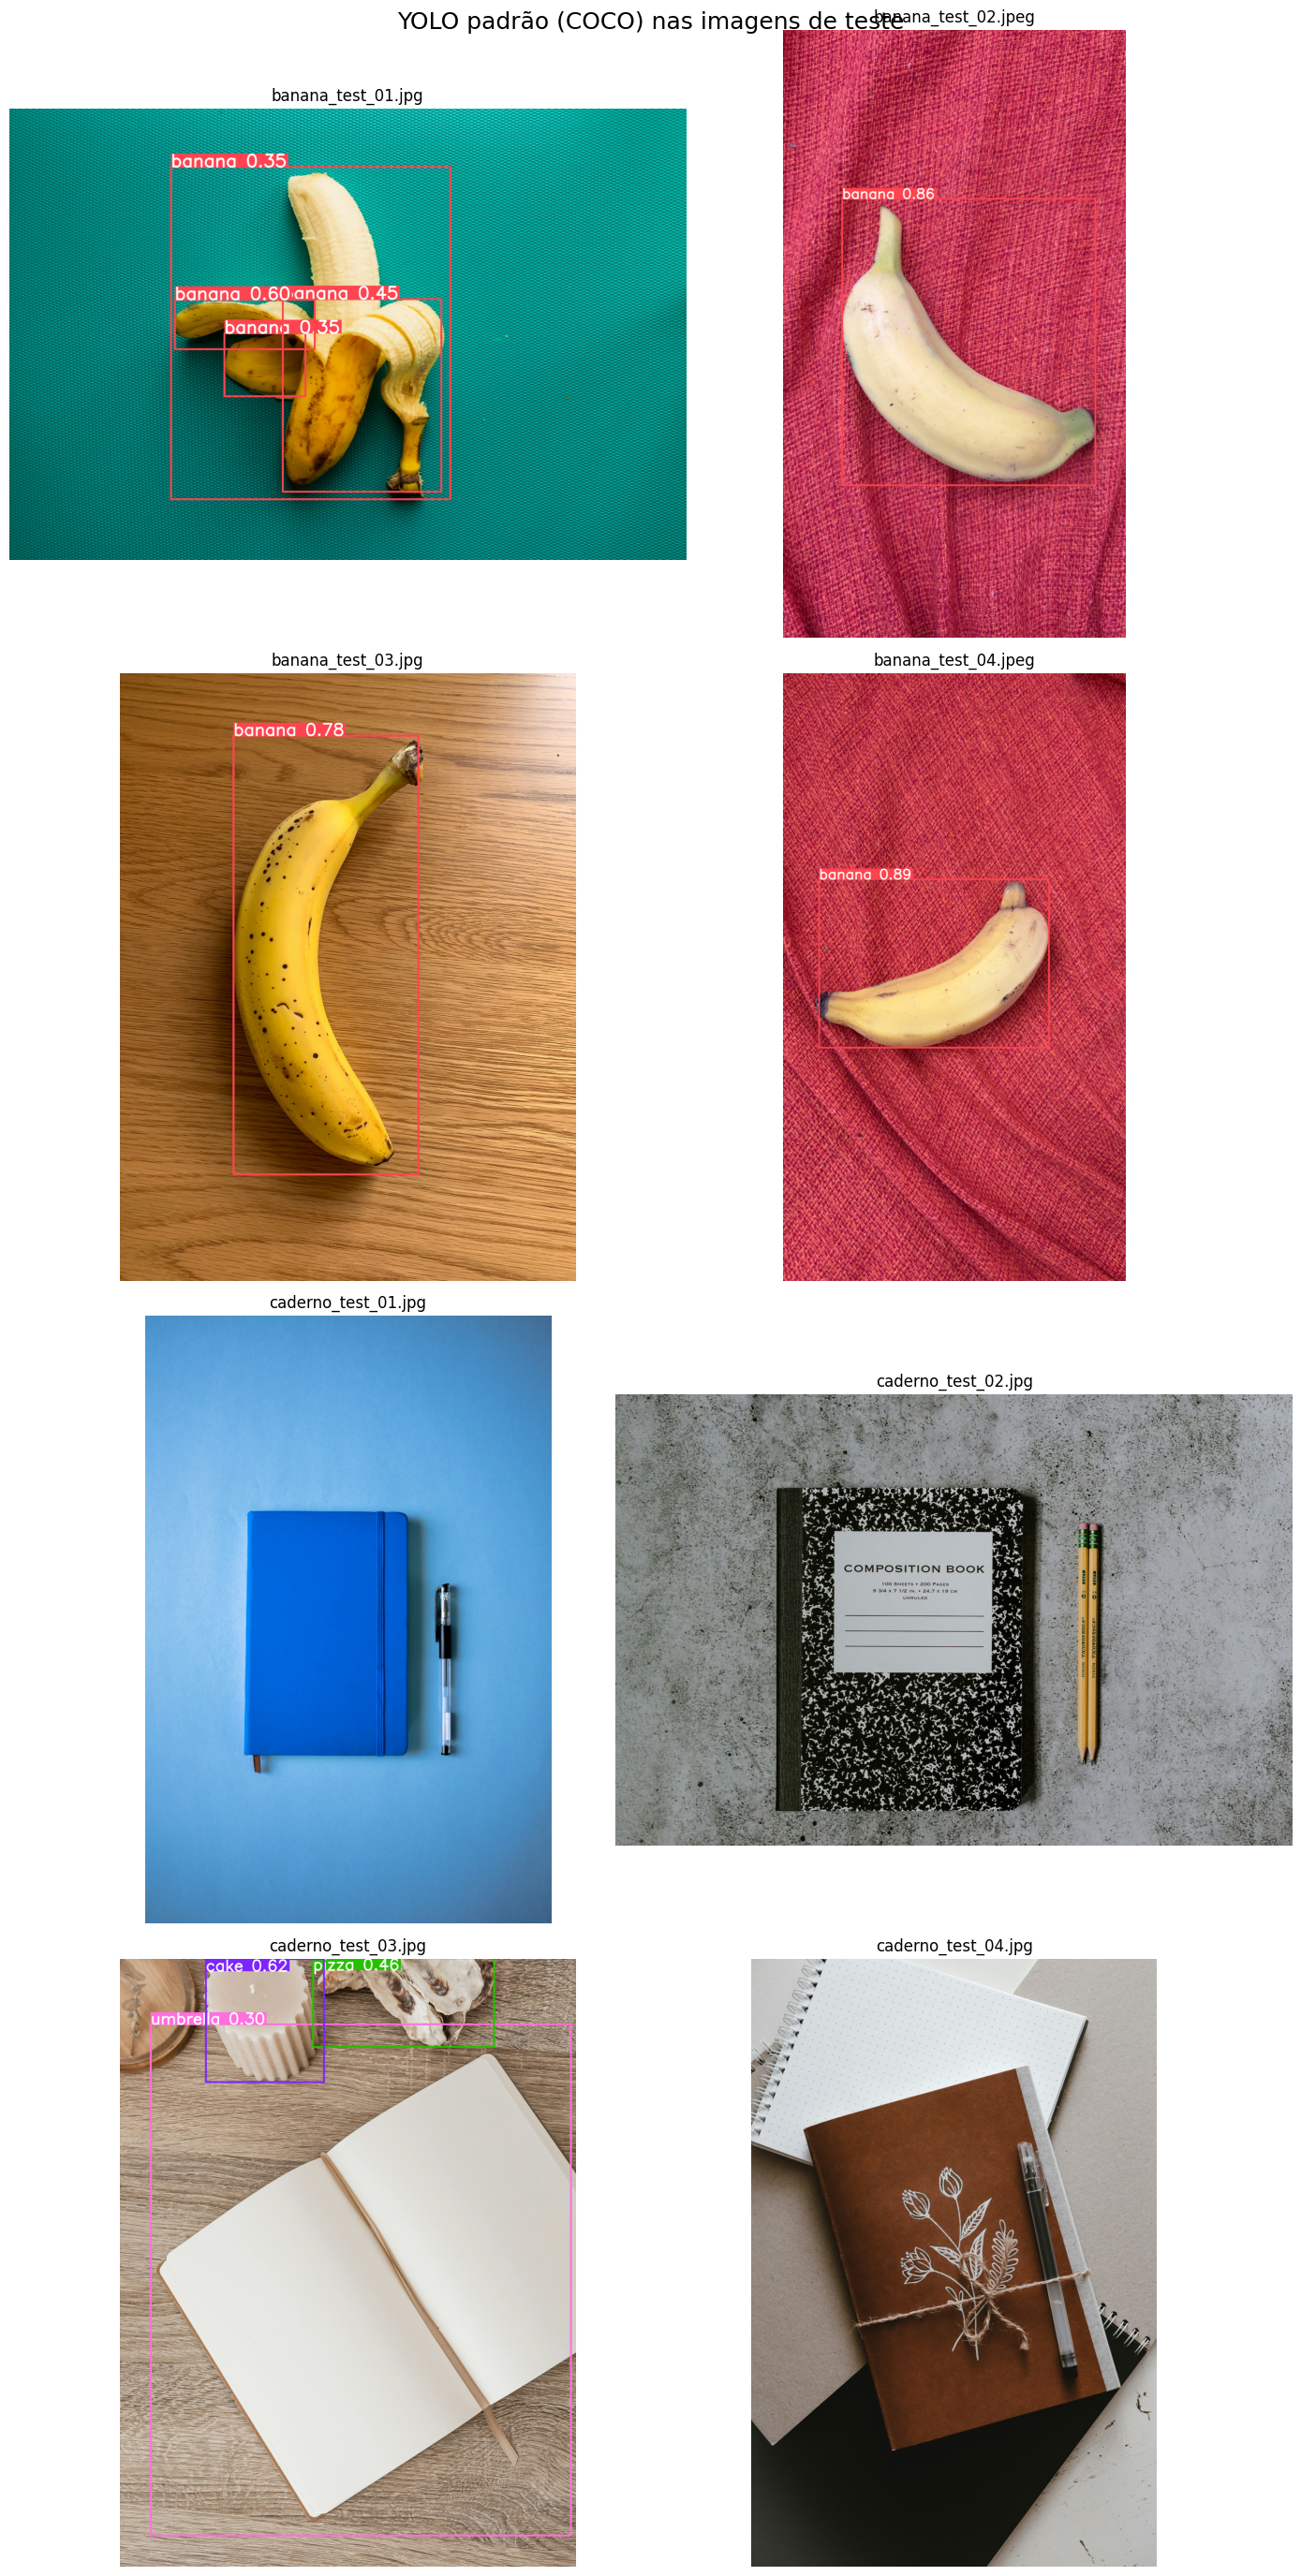

In [17]:
import matplotlib.image as mpimg

# Imagens de teste com as caixas desenhadas pelo YOLO padrão
imagens_b = resultado_b.render()
fig, eixos = plt.subplots(4, 2, figsize=(14, 28))
fig.suptitle('YOLO padrão (COCO) nas imagens de teste', fontsize=18)
for ax in eixos.flat:
    ax.axis('off')
for ax, img, arq in zip(eixos.flat, imagens_b, arqs_teste):
    ax.imshow(img)
    ax.set_title(os.path.basename(arq), fontsize=12)
plt.tight_layout()
plt.savefig('/content/deteccoes_yolo_padrao.png', dpi=130, bbox_inches='tight')
plt.show()

## Etapa 6: Tempo de inferência
Para cada abordagem, meço o **tempo por imagem, do arquivo até a classe prevista** (leitura, pré-processamento, rede e pós-processamento), nas 8 imagens de teste, com 5 repetições e um aquecimento antes. Todos rodam no **mesmo ambiente (GPU T4)**.

> Como os arquivos originais são fotos grandes, a **leitura da imagem pesa** no tempo de todas as abordagens. O resultado reflete o uso "de ponta a ponta", e não só a rede.

In [18]:
def medir_inferencia(pred, caminhos, repeticoes=5):
    # Tempo médio por imagem, em milissegundos
    pred(caminhos[0])  # aquecimento (a primeira chamada é mais lenta)
    if device.type == 'cuda': torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(repeticoes):
        for c in caminhos:
            pred(c)
    if device.type == 'cuda': torch.cuda.synchronize()
    return (time.perf_counter() - t0) / (repeticoes * len(caminhos)) * 1000

tempo_inf = {nome: medir_inferencia(pred, arqs_teste) for nome, pred in preditores.items()}
for nome, t in tempo_inf.items():
    print(f'{nome:30s} | {t:6.1f} ms por imagem')

A) YOLO customizado (30 ép.)   |  407.7 ms por imagem
A) YOLO customizado (60 ép.)   |  413.8 ms por imagem
B) YOLO padrão (COCO)          |  398.1 ms por imagem
C) CNN do zero                 |  464.9 ms por imagem


## Etapa 7: Tabela comparativa
Reúno tudo numa tabela. Os valores de **mAP@0.5 e tempo de treino do YOLO customizado** vêm da Entrega 1 (notebook anterior). O mAP não existe para a CNN (ela não localiza objetos) e não é comparável para o YOLO padrão (as classes do COCO são diferentes das minhas).

In [19]:
# Valores da Entrega 1 (notebook anterior): mAP@0.5 no teste e tempo de treino
MAP50_TESTE_A = {'A) YOLO customizado (30 ép.)': 0.945, 'A) YOLO customizado (60 ép.)': 0.829}
TREINO_A = {'A) YOLO customizado (30 ép.)': '2,4 min', 'A) YOLO customizado (60 ép.)': '3,1 min'}

# Tamanho do arquivo de cada modelo, em MB
tamanho = {
    'A) YOLO customizado (30 ép.)': os.path.getsize(PESOS_30) / 1e6,
    'A) YOLO customizado (60 ép.)': os.path.getsize(PESOS_60) / 1e6,
    'B) YOLO padrão (COCO)': os.path.getsize('/content/yolov5/yolov5s.pt') / 1e6,
    'C) CNN do zero': os.path.getsize('/content/cnn_banana_caderno.pt') / 1e6,
}

linhas = []
for nome in preditores:
    sem_det = sum(p == -1 for p in previsoes[(nome, 'test')])
    linhas.append({
        'Abordagem': nome,
        'Acurácia validação': round(acuracia[(nome, 'val')], 3),
        'Acurácia teste': round(acuracia[(nome, 'test')], 3),
        'Sem detecção (teste)': sem_det,
        'mAP@0.5 teste': MAP50_TESTE_A.get(nome, '-'),
        'Tempo de treino': TREINO_A.get(nome, 'nenhum' if nome.startswith('B') else f'{tempo_cnn/60:.1f} min'),
        'Inferência (ms/img)': round(tempo_inf[nome], 1),
        'Tamanho (MB)': round(tamanho[nome], 1),
    })
tabela = pd.DataFrame(linhas)
display(tabela)
tabela.to_csv('/content/tabela_comparativa_entrega2.csv', index=False)

,Abordagem,Acurácia validação,Acurácia teste,Sem detecção (teste),mAP@0.5 teste,Tempo de treino,Inferência (ms/img),Tamanho (MB)
0,A) YOLO customizado (30 ép.),0.875,0.875,1,0.945,"2,4 min",407.7,14.4
1,A) YOLO customizado (60 ép.),0.750,0.625,2,0.829,"3,1 min",413.8,14.4
2,B) YOLO padrão (COCO),0.750,0.500,4,-,nenhum,398.1,14.8
3,C) CNN do zero,0.875,1.000,0,-,0.1 min,464.9,0.4


## Etapa 8: Análise crítica

### Resumo dos resultados

| Abordagem | Acurácia validação | Acurácia teste | Sem detecção (teste) | mAP@0.5 teste | Tempo de treino | Inferência (ms/img) | Tamanho (MB) |
|---|---|---|---|---|---|---|---|
| A) YOLO customizado (30 ép.) | 0,875 | 0,875 | 1 | 0,945 | 2,4 min | 407,7 | 14,4 |
| A) YOLO customizado (60 ép.) | 0,750 | 0,625 | 2 | 0,829 | 3,1 min | 413,8 | 14,4 |
| B) YOLO padrão (COCO) | 0,750 | 0,500 | 4 | - | nenhum | 398,1 | 14,8 |
| C) CNN do zero | 0,875 | 1,000 | - | - | 7 s (0,1 min) | 464,9 | 0,4 |

### 1. Facilidade de uso e integração
- **B) YOLO padrão:** é o mais simples: carregar os pesos prontos e rodar, sem dados, rótulos ou treino. Mas só reconhece as 80 classes do COCO, o que limitou o resultado (ver item 2).
- **A) YOLO customizado:** exigiu montar o dataset, **rotular com caixas** (a etapa mais trabalhosa), treinar e conferir os arquivos. Depois de pronto, o `best.pt` se integra facilmente (o capítulo 3 mostra, por exemplo, a integração com o ESP32-CAM) e o YOLO devolve **onde** está o objeto, não só **qual** é.
- **C) CNN do zero:** exigiu escrever a arquitetura, o laço de treino e o *data augmentation*, mas **não precisa de caixas**, só de um rótulo por imagem (muito mais barato de produzir). Em compensação, só diz a classe da imagem inteira, sem localizar nem contar objetos.

### 2. Precisão
- **Teste:** a CNN acertou **8 de 8** imagens (1,000), o YOLO customizado de 30 épocas acertou **7 de 8** (0,875), o de 60 épocas **5 de 8** (0,625) e o YOLO padrão **4 de 8** (0,500).
- **Bananas:** as quatro abordagens acertaram as 4 bananas de teste. A diferença está toda nos **cadernos**.
- **YOLO padrão (B):** **não reconheceu nenhum dos 4 cadernos**. Mesmo tratando `book` como `caderno`, a classe `book` não foi detectada em nenhuma imagem; na `caderno_test_03`, ele viu `cake`, `pizza` e `umbrella` (a vela, a ostra e o caderno aberto). Isso mostra o limite de um modelo treinado em classes fixas: o que não está no COCO não é reconhecido. Ele também fragmentou a banana descascada em 4 caixas, embora a classe da imagem tenha ficado correta.
- **YOLO customizado:** o de 30 épocas errou só a `caderno_test_03` (caderno aberto sobre madeira, não detectado). O de 60 épocas errou 3 cadernos: não detectou 2 e classificou a `caderno_test_03` como `banana`. Isso confirma o resultado da Entrega 1: **treinar por mais tempo não melhorou o modelo**.
- **CNN:** acertou os 4 cadernos, inclusive o caderno aberto que o YOLO não encontrou.
- **Cuidado com a conclusão:** com 8 imagens de teste, a diferença entre a CNN (8/8) e o YOLO de 30 épocas (7/8) é de **uma única imagem**. Não dá para afirmar que a CNN é melhor. Além disso, a comparação não é totalmente igual: a CNN **sempre devolve uma das duas classes** (nunca diz "nada"), enquanto o YOLO precisa detectar o objeto com confiança mínima de 0,25 **e** dizer onde ele está, que é uma tarefa mais difícil.
- **Overfitting na CNN:** a acurácia de treino ficou perto de 0,92, mas a de validação oscilou entre 0,38 e 0,88, e a perda de validação (entre 0,7 e 2,3) ficou bem acima da de treino (cerca de 0,2). É um sinal de overfitting e de instabilidade, agravado por uma validação de só 8 imagens. A melhor época (31) foi escolhida pela validação, e o teste não foi usado, mas o resultado de 8/8 deve ser visto com cautela.

### 3. Tempo de treinamento e customização
- **B:** nenhum.
- **A:** cerca de 2,4 min (30 épocas) e 3,1 min (60 épocas) na T4, **mais** o tempo humano de rotular 72 imagens com caixas.
- **C:** **7 segundos** (40 épocas, melhor época: 31), na mesma GPU. É cerca de 20 a 27 vezes mais rápido que o YOLO, e dispensa o trabalho de rotular caixas.

### 4. Tempo de inferência e tamanho
- Os tempos ficaram todos entre **398 e 465 ms por imagem**: YOLO padrão 398,1; YOLO customizado 407,7 (30 ép.) e 413,8 (60 ép.); CNN 464,9.
- **Atenção ao que esse número mede:** ele vai do arquivo até a classe prevista e inclui a **leitura e o redimensionamento de fotos grandes**, que pesam em todos. Por isso as diferenças são pequenas e **não refletem a velocidade da rede em si**. A CNN aparece como a mais lenta porque o meu pré-processamento (correção de rotação e redução da foto em tamanho original, na CPU) é mais pesado que o do YOLO, e não porque a rede seja lenta: ela tem só 0,4 MB. Nos logs do `val.py` da Entrega 1, o YOLO gastou cerca de 12 a 20 ms de inferência (mais 10 a 29 ms de NMS) por imagem já carregada.
- **Tamanho:** a CNN (0,4 MB) é cerca de **36 vezes menor** que o YOLOv5s (14,4 a 14,8 MB), o que importa em dispositivos limitados, como o ESP32-CAM e o Jetson Nano citados no capítulo 3.

### 5. Pontos fortes e limitações do trabalho
- **Pontos fortes:** mesma base e mesma divisão nas três abordagens, o que torna a comparação justa; teste nunca usado no treino; mesmas métricas e mesmo ambiente de medição; análise imagem por imagem, que mostra *onde* cada modelo erra.
- **Limitações:** base muito pequena (64 treino, 8 validação, 8 teste), com fotos do Unsplash no teste; o YOLO padrão foi adaptado (`book` como `caderno`); a validação é otimista para A e C; o tempo de inferência inclui a leitura de fotos grandes e não mede a rede isoladamente; a comparação por imagem favorece a CNN, que não tem a opção de "não detectar".

### 6. Qual abordagem usar, e em que cenário
- **YOLO padrão (B):** quando os objetos de interesse já estão no COCO (pessoas, carros, bananas) e não há tempo ou dados para treinar. Aqui serviu para bananas, mas **falhou em todos os cadernos**.
- **YOLO customizado (A):** quando é preciso **reconhecer e localizar** objetos específicos do cliente, e vale investir em rotular. Foi a melhor opção que também informa a posição do objeto (30 épocas: 7/8 e mAP@0.5 de 0,945).
- **CNN do zero (C):** quando basta **classificar a imagem inteira**, os rótulos são baratos e o modelo precisa ser leve e rápido de treinar. Acertou todo o teste, mas com uma validação instável, então precisa de bem mais dados antes de ser confiável.

**Recomendação ao cliente:** se o cliente só precisa saber **qual objeto aparece na foto**, vale começar pela CNN, pela simplicidade, pelo tamanho e pelo custo, ampliando antes a base de imagens para confirmar a estabilidade. Se precisa **localizar** os objetos (contar, recortar, acionar algo na posição), a melhor escolha foi o **YOLO customizado de 30 épocas**. O **YOLO padrão** só se justifica para classes que já existem no COCO, e **mais épocas** não ajudaram nenhum dos modelos.